In [21]:
from google.colab import userdata
import sys, os, subprocess

TOKEN = userdata.get('GITHUB_TOKEN')
USERNAME = "vedika0806"
REPO = "data266-5937"
HW = "hw5"

os.system(f"git clone https://{TOKEN}@github.com/{USERNAME}/{REPO}.git /content/{REPO}")

sys.path.append(f"/content/{REPO}/common")
import colab_bootstrap, importlib
importlib.reload(colab_bootstrap)
from colab_bootstrap import setup_repo, get_logger, git_commit_push, git_tag_push

REPO_PATH = f"/content/{REPO}"
HW_PATH = setup_repo(HW, USERNAME, REPO, TOKEN)
logger = get_logger(HW_PATH)

logger.info(f"=== Session started for {HW} ===")
git_commit_push(REPO_PATH, f"{HW}: session start")

INFO:/content/data266-5937/hw5:=== Session started for hw5 ===


Working directory: /content/data266-5937/hw5
[main 23e19d8] hw5: session start
 1 file changed, 1 insertion(+)
 


In [2]:
!pip install -q transformers peft datasets accelerate evaluate rouge_score

  Preparing metadata (setup.py) ... done
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 84.1/84.1 kB 4.8 MB/s eta 0:00:00


In [3]:
SID4 = 5937
SEED = SID4
SLICE = SID4 % 1000
HP_ID = SID4 % 6
CLS_A = SID4 % 10
CLS_B = (CLS_A + 1 + ((SID4 // 10) % 9)) % 10

print(f"SID4={SID4}, SEED={SEED}, SLICE={SLICE}, HP_ID={HP_ID}, CLS_A={CLS_A}, CLS_B={CLS_B}")
logger.info(f"Params: SID4={SID4}, SEED={SEED}, SLICE={SLICE}, HP_ID={HP_ID}, CLS_A={CLS_A}, CLS_B={CLS_B}")

import torch, random, numpy as np, json
random.seed(SEED); np.random.seed(SEED); torch.manual_seed(SEED)
device = "cuda" if torch.cuda.is_available() else "cpu"
print("Device:", device)

INFO:/content/data266-5937/hw5:Params: SID4=5937, SEED=5937, SLICE=937, HP_ID=3, CLS_A=7, CLS_B=6


SID4=5937, SEED=5937, SLICE=937, HP_ID=3, CLS_A=7, CLS_B=6
Device: cuda


In [4]:
from datasets import load_dataset

ds = load_dataset("neil-code/dialogsum-test")
print(ds)   # check which splits exist (train / validation / test)

PROMPT = "Summarize the following conversation.\n\n{dialogue}\n\nSummary:"

def to_io(ex):
    return {"input": PROMPT.format(dialogue=ex["dialogue"]), "target": ex["summary"]}

processed = ds.map(to_io)

# Show 2 processed samples
first_split = list(ds.keys())[0]
for i in range(2):
    s = processed[first_split][i]
    print(f"--- Sample {i} ---\nINPUT:\n{s['input']}\n\nTARGET:\n{s['target']}\n")

logger.info("Task 1: dataset loaded and converted to input/target")

README.md:   0%|          | 0.00/4.56k [00:00<?, ?B/s]

train.csv:   0%|          | 0.00/1.81M [00:00<?, ?B/s]

validation.csv:   0%|          | 0.00/441k [00:00<?, ?B/s]

test.csv:   0%|          | 0.00/447k [00:00<?, ?B/s]

Generating train split:   0%|          | 0/1999 [00:00<?, ? examples/s]

...

Map:   0%|          | 0/1999 [00:00<?, ? examples/s]

Map:   0%|          | 0/499 [00:00<?, ? examples/s]

Map:   0%|          | 0/499 [00:00<?, ? examples/s]

INFO:/content/data266-5937/hw5:Task 1: dataset loaded and converted to input/target


--- Sample 0 ---
INPUT:
Summarize the following conversation.

#Person1#: Hi, Mr. Smith. I'm Doctor Hawkins. Why are you here today?
#Person2#: I found it would be a good idea to get a check-up.
#Person1#: Yes, well, you haven't had one for 5 years. You should have one every year.
#Person2#: I know. I figure as long as there is nothing wrong, why go see the doctor?
#Person1#: Well, the best way to avoid serious illnesses is to find out about them early. So try to come at least once a year for your own good.
#Person2#: Ok.
#Person1#: Let me see here. Your eyes and ears look fine. Take a deep breath, please. Do you smoke, Mr. Smith?
#Person2#: Yes.
#Person1#: Smoking is the leading cause of lung cancer and heart disease, you know. You really should quit.
#Person2#: I've tried hundreds of times, but I just can't seem to kick the habit.
#Person1#: Well, we have classes and some medications that might help. I'll give you more information before you leave.
#Person2#: Ok, thanks doctor.

Summ

In [5]:
train_raw = processed["train"].shuffle(seed=SEED).select(range(1500))
eval_raw  = processed["test"].shuffle(seed=SEED).select(range(50))

In [6]:
demo = [eval_raw[0], eval_raw[1]]
demo_inputs = [d["input"] for d in demo]
demo_refs   = [d["target"] for d in demo]
logger.info("Selected 2 fixed demo dialogues from eval set")
git_commit_push(REPO_PATH, f"{HW}: task 1 data preparation")

INFO:/content/data266-5937/hw5:Selected 2 fixed demo dialogues from eval set


[main 47f91fb] hw5: task 1 data preparation
 1 file changed, 3 insertions(+)
 


In [7]:
from transformers import AutoTokenizer, AutoModelForSeq2SeqLM

MODEL_NAME = "google/flan-t5-small"
tokenizer = AutoTokenizer.from_pretrained(MODEL_NAME)

def build_base():
    # Reload fresh each time: get_peft_model() modifies the base model IN PLACE
    return AutoModelForSeq2SeqLM.from_pretrained(MODEL_NAME).to(device)

@torch.no_grad()
def generate(model, texts, max_new_tokens=64):
    model.eval()
    enc = tokenizer(texts, return_tensors="pt", padding=True,
                    truncation=True, max_length=512).to(device)
    out = model.generate(**enc, max_new_tokens=max_new_tokens, num_beams=4)
    return tokenizer.batch_decode(out, skip_special_tokens=True)

base_model = build_base()
baseline_outputs = generate(base_model, demo_inputs)

for i, o in enumerate(baseline_outputs):
    print(f"--- Baseline {i} ---\nREF:  {demo_refs[i]}\nPRED: {o}\n")

with open(f"{HW_PATH}/baseline_outputs.json", "w") as f:
    json.dump({"inputs": demo_inputs, "refs": demo_refs, "baseline": baseline_outputs}, f, indent=2)

logger.info("Task 2: baseline inference saved to baseline_outputs.json")
git_commit_push(REPO_PATH, f"{HW}: task 2 baseline inference")

config.json:   0%|          | 0.00/1.40k [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/2.54k [00:00<?, ?B/s]

spiece.model: reconstructing file:   0%|          |  0.00B /  792kB            

spiece.model: downloading bytes:           |  0.00B            

tokenizer.json:   0%|          | 0.00/2.42M [00:00<?, ?B/s]

...

Loading weights:   0%|          | 0/190 [00:00<?, ?it/s]

[transformers] The tied weights mapping and config for this model specifies to tie shared.weight to lm_head.weight, but both are present in the checkpoints with different values, so we will NOT tie them. You should update the config with `tie_word_embeddings=False` to silence this warning.


generation_config.json:   0%|          | 0.00/147 [00:00<?, ?B/s]

INFO:/content/data266-5937/hw5:Task 2: baseline inference saved to baseline_outputs.json


--- Baseline 0 ---
REF:  Mr. Foster wants the training manuals to be sent this afternoon but Mr. Blake explains that they haven't been printed out yet.
PRED: Mr. Blake, I'd like to know if you can send over these training manuals to Mr. Foster's office tomorrow afternoon.

--- Baseline 1 ---
REF:  Johnson is teaching #Person1# how to use the training machines. He introduces a training card that allows #Person1# to keep track of the weight used on each machine. #Person1# is exhausted when there are still 7 machines left. Johnson suggests #Person1# stop to train and go through the rest of the machines next time.
PRED: I'm sorry, I don't want to start on the machines. I'm sorry, I don't want to start on the machines.

[main 80edb15] hw5: task 2 baseline inference
 2 files changed, 15 insertions(+)
 create mode 100644 hw5/baseline_outputs.json
 


In [9]:
!
!pip install --upgrade torchao
from peft import LoraConfig, get_peft_model, TaskType

def count_params(m):
    total = sum(p.numel() for p in m.parameters())
    trainable = sum(p.numel() for p in m.parameters() if p.requires_grad)
    return total, trainable

def make_lora_model(r, alpha, dropout=0.05):
    cfg = LoraConfig(
        r=r, lora_alpha=alpha, lora_dropout=dropout,
        target_modules=["q", "v"],           # T5 attention query & value projections
        task_type=TaskType.SEQ_2_SEQ_LM, bias="none",
    )
    return get_peft_model(build_base(), cfg)

R_MAIN, ALPHA_MAIN, DROPOUT = 16, 32, 0.05
lora_model = make_lora_model(R_MAIN, ALPHA_MAIN, DROPOUT)

total, trainable = count_params(lora_model)
print(f"LoRA config: r={R_MAIN}, alpha={ALPHA_MAIN}, dropout={DROPOUT}")
print(f"Total parameters:     {total:,}")
print(f"Trainable parameters: {trainable:,} ({100*trainable/total:.2f}%)")
lora_model.print_trainable_parameters()

logger.info(f"Task 3: LoRA r={R_MAIN} alpha={ALPHA_MAIN} dropout={DROPOUT}; total={total}, trainable={trainable}")
git_commit_push(REPO_PATH, f"{HW}: task 3 LoRA applied")

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 3.4/3.4 MB 56.5 MB/s eta 0:00:00
  Attempting uninstall: torchao
    Found existing installation: torchao 0.10.0
    Uninstalling torchao-0.10.0:
      Successfully uninstalled torchao-0.10.0


Loading weights:   0%|          | 0/190 [00:00<?, ?it/s]

[transformers] The tied weights mapping and config for this model specifies to tie shared.weight to lm_head.weight, but both are present in the checkpoints with different values, so we will NOT tie them. You should update the config with `tie_word_embeddings=False` to silence this warning.
INFO:/content/data266-5937/hw5:Task 3: LoRA r=16 alpha=32 dropout=0.05; total=77649280, trainable=688128


LoRA config: r=16, alpha=32, dropout=0.05
Total parameters:     77,649,280
Trainable parameters: 688,128 (0.89%)
trainable params: 688,128 || all params: 77,649,280 || trainable%: 0.8862
[main 9051c48] hw5: task 3 LoRA applied
 1 file changed, 1 insertion(+)
 


In [10]:
from transformers import DataCollatorForSeq2Seq, Trainer, TrainingArguments

def tokenize(batch):
    x = tokenizer(batch["input"], max_length=512, truncation=True)
    y = tokenizer(text_target=batch["target"], max_length=128, truncation=True)
    x["labels"] = y["input_ids"]
    return x

train_tok = train_raw.map(tokenize, batched=True, remove_columns=train_raw.column_names)

def train_lora(model, tag, epochs=2, lr=1e-3):
    args = TrainingArguments(
        output_dir=f"/content/tmp_{tag}",
        per_device_train_batch_size=8,
        num_train_epochs=epochs,
        learning_rate=lr,
        logging_steps=20,
        save_strategy="no",
        report_to="none",
        seed=SEED,
        fp16=False,
    )
    trainer = Trainer(model=model, args=args, train_dataset=train_tok,
                      data_collator=DataCollatorForSeq2Seq(tokenizer, model=model))
    result = trainer.train()
    return trainer, result

trainer, result = train_lora(lora_model, f"r{R_MAIN}")

losses = [(h["step"], h["loss"]) for h in trainer.state.log_history if "loss" in h]
final_loss = losses[-1][1]
print(f"Final logged training loss: {final_loss:.4f}")
print(f"Average training loss:      {result.training_loss:.4f}")

# Save adapters (small: ~ MBs)
lora_model.save_pretrained(f"{HW_PATH}/lora_r{R_MAIN}_adapter")
logger.info(f"Task 4: trained r={R_MAIN}, final loss={final_loss:.4f}; adapter saved")

Map:   0%|          | 0/1500 [00:00<?, ? examples/s]

Step,Training Loss
20,1.892376
40,1.611410
60,1.577725
80,1.570846
100,1.601869
120,1.472479
140,1.528750
160,1.534799
180,1.519853
200,1.452007


Final logged training loss: 1.4459
Average training loss:      1.5241


INFO:/content/data266-5937/hw5:Task 4: trained r=16, final loss=1.4459; adapter saved


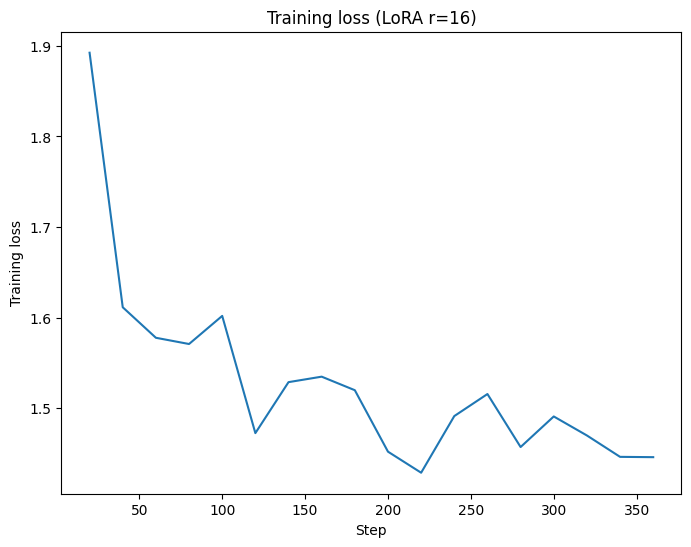

45470 bytes
[main 1394d0e] hw5: task 4 fine-tuning r=16, adapter + loss curve
 5 files changed, 252 insertions(+)
 create mode 100644 hw5/lora_r16_adapter/README.md
 create mode 100644 hw5/lora_r16_adapter/adapter_config.json
 create mode 100644 hw5/lora_r16_adapter/adapter_model.safetensors
 create mode 100644 hw5/loss_curve_r16.png
 


In [11]:
import matplotlib.pyplot as plt, os

plt.figure(figsize=(8,6))
plt.plot([s for s,_ in losses], [l for _,l in losses])
plt.xlabel("Step"); plt.ylabel("Training loss")
plt.title(f"Training loss (LoRA r={R_MAIN})")
plt.savefig(f"{HW_PATH}/loss_curve_r{R_MAIN}.png", bbox_inches="tight", dpi=150)
plt.show(); plt.close()
print(os.path.getsize(f"{HW_PATH}/loss_curve_r{R_MAIN}.png"), "bytes")

git_commit_push(REPO_PATH, f"{HW}: task 4 fine-tuning r={R_MAIN}, adapter + loss curve")

In [12]:
ft_outputs_r16 = generate(lora_model, demo_inputs)

for i, o in enumerate(ft_outputs_r16):
    print(f"--- Fine-tuned (r=16) {i} ---\nPRED: {o}\n")

with open(f"{HW_PATH}/finetuned_outputs_r16.json", "w") as f:
    json.dump({"finetuned_r16": ft_outputs_r16}, f, indent=2)

logger.info("Task 5: post-fine-tuning inference saved")
git_commit_push(REPO_PATH, f"{HW}: task 5 post-FT inference")

INFO:/content/data266-5937/hw5:Task 5: post-fine-tuning inference saved


--- Fine-tuned (r=16) 0 ---
PRED: Mr. Blake tells Mr. Foster if he can send over training manuals to Mr. Foster's office tomorrow afternoon.

--- Fine-tuned (r=16) 1 ---
PRED: Johnson tells Johnson how to get started using the machines. Johnson tells Johnson how to get started using the machines. Johnson tells Johnson how to get started using the machines. Johnson tells Johnson how to get started using the machines. Johnson tells Johnson how to get started using the machines.

[main 2809858] hw5: task 5 post-FT inference
 2 files changed, 7 insertions(+)
 create mode 100644 hw5/finetuned_outputs_r16.json
 


In [13]:
for i in range(2):
    print(f"=== Dialogue {i} ===")
    print("REFERENCE :", demo_refs[i])
    print("BEFORE FT :", baseline_outputs[i])
    print("AFTER FT  :", ft_outputs_r16[i])
    print()

=== Dialogue 0 ===
REFERENCE : Mr. Foster wants the training manuals to be sent this afternoon but Mr. Blake explains that they haven't been printed out yet.
BEFORE FT : Mr. Blake, I'd like to know if you can send over these training manuals to Mr. Foster's office tomorrow afternoon.
AFTER FT  : Mr. Blake tells Mr. Foster if he can send over training manuals to Mr. Foster's office tomorrow afternoon.

=== Dialogue 1 ===
REFERENCE : Johnson is teaching #Person1# how to use the training machines. He introduces a training card that allows #Person1# to keep track of the weight used on each machine. #Person1# is exhausted when there are still 7 machines left. Johnson suggests #Person1# stop to train and go through the rest of the machines next time.
BEFORE FT : I'm sorry, I don't want to start on the machines. I'm sorry, I don't want to start on the machines.
AFTER FT  : Johnson tells Johnson how to get started using the machines. Johnson tells Johnson how to get started using the machines.

In [14]:
import evaluate
rouge = evaluate.load("rouge")

def rouge_eval(model, n=50):
    preds = []
    texts = eval_raw["input"][:n]
    for i in range(0, n, 10):
        preds += generate(model, texts[i:i+10])
    r = rouge.compute(predictions=preds, references=eval_raw["target"][:n])
    return {k: round(v, 4) for k, v in r.items()}

# r=4
R_SMALL, ALPHA_SMALL = 4, 8
model_r4 = make_lora_model(R_SMALL, ALPHA_SMALL, DROPOUT)
t4, res4 = train_lora(model_r4, f"r{R_SMALL}")
loss_r4 = [h["loss"] for h in t4.state.log_history if "loss" in h][-1]
total4, trainable4 = count_params(model_r4)
model_r4.save_pretrained(f"{HW_PATH}/lora_r{R_SMALL}_adapter")
ft_outputs_r4 = generate(model_r4, demo_inputs)

# Metrics table
results = {
    "baseline": rouge_eval(base_model),
    "r4":  rouge_eval(model_r4),
    "r16": rouge_eval(lora_model),
}
print("Trainable params  r=4:", trainable4, "| r=16:", trainable)
print("Final loss        r=4:", round(loss_r4,4), "| r=16:", round(final_loss,4))
for k, v in results.items():
    print(k, v)

for i in range(2):
    print(f"\n=== Dialogue {i} ===")
    print("REF :", demo_refs[i])
    print("BASE:", baseline_outputs[i])
    print("r=4 :", ft_outputs_r4[i])
    print("r=16:", ft_outputs_r16[i])

with open(f"{HW_PATH}/rank_experiment.json", "w") as f:
    json.dump({"rouge": results, "loss": {"r4": loss_r4, "r16": final_loss},
               "trainable": {"r4": trainable4, "r16": trainable},
               "outputs_r4": ft_outputs_r4, "outputs_r16": ft_outputs_r16}, f, indent=2)

logger.info(f"Task 7: r=4 vs r=16 done. ROUGE={results}")
git_commit_push(REPO_PATH, f"{HW}: task 7 rank experiment r=4 vs r=16")

Loading weights:   0%|          | 0/190 [00:00<?, ?it/s]

[transformers] The tied weights mapping and config for this model specifies to tie shared.weight to lm_head.weight, but both are present in the checkpoints with different values, so we will NOT tie them. You should update the config with `tie_word_embeddings=False` to silence this warning.


Step,Training Loss
20,2.092705
40,1.693523
60,1.624578
80,1.620202
100,1.640893
120,1.504180
140,1.563680
160,1.574180
180,1.548672
200,1.496753


INFO:/content/data266-5937/hw5:Task 7: r=4 vs r=16 done. ROUGE={'baseline': {'rouge1': np.float64(0.1456), 'rouge2': np.float64(0.0444), 'rougeL': np.float64(0.1217), 'rougeLsum': np.float64(0.1211)}, 'r4': {'rouge1': np.float64(0.3673), 'rouge2': np.float64(0.1199), 'rougeL': np.float64(0.2921), 'rougeLsum': np.float64(0.2921)}, 'r16': {'rouge1': np.float64(0.3719), 'rouge2': np.float64(0.1222), 'rougeL': np.float64(0.2979), 'rougeLsum': np.float64(0.299)}}


Trainable params  r=4: 172032 | r=16: 688128
Final loss        r=4: 1.5002 | r=16: 1.4459
baseline {'rouge1': np.float64(0.1456), 'rouge2': np.float64(0.0444), 'rougeL': np.float64(0.1217), 'rougeLsum': np.float64(0.1211)}
r4 {'rouge1': np.float64(0.3673), 'rouge2': np.float64(0.1199), 'rougeL': np.float64(0.2921), 'rougeLsum': np.float64(0.2921)}
r16 {'rouge1': np.float64(0.3719), 'rouge2': np.float64(0.1222), 'rougeL': np.float64(0.2979), 'rougeLsum': np.float64(0.299)}

=== Dialogue 0 ===
REF : Mr. Foster wants the training manuals to be sent this afternoon but Mr. Blake explains that they haven't been printed out yet.
BASE: Mr. Blake, I'd like to know if you can send over these training manuals to Mr. Foster's office tomorrow afternoon.
r=4 : Mr. Blake tells Mr. Foster to send over training manuals to Mr. Foster. Mr. Foster will drop them off tomorrow afternoon. Mr. Foster will be back tomorrow before 1 o'clock.
r=16: Mr. Blake tells Mr. Foster if he can send over training manuals 

In [15]:
analysis = f"""
## Task 7: LoRA Rank Experiment

| Config | Trainable params | Final loss | ROUGE-1 | ROUGE-L |
|---|---|---|---|---|
| Baseline | 0 | - | {results['baseline']['rouge1']} | {results['baseline']['rougeL']} |
| r=4 (alpha=8) | {trainable4:,} | {loss_r4:.4f} | {results['r4']['rouge1']} | {results['r4']['rougeL']} |
| r=16 (alpha=32) | {trainable:,} | {final_loss:.4f} | {results['r16']['rouge1']} | {results['r16']['rougeL']} |

(Write your analysis here: how did output quality change between r=4 and r=16? Is the difference meaningful?)
"""
with open(f"{HW_PATH}/METRICS.md", "a") as f:
    f.write(analysis)
print(analysis)
git_commit_push(REPO_PATH, f"{HW}: add rank experiment analysis to METRICS.md")


## Task 7: LoRA Rank Experiment

| Config | Trainable params | Final loss | ROUGE-1 | ROUGE-L |
|---|---|---|---|---|
| Baseline | 0 | - | 0.1456 | 0.1217 |
| r=4 (alpha=8) | 172,032 | 1.5002 | 0.3673 | 0.2921 |
| r=16 (alpha=32) | 688,128 | 1.4459 | 0.3719 | 0.2979 |

(Write your analysis here: how did output quality change between r=4 and r=16? Is the difference meaningful?)

[main 7169df2] hw5: add rank experiment analysis to METRICS.md
 1 file changed, 10 insertions(+)
 create mode 100644 hw5/METRICS.md
 


In [16]:
comparison = """
## Task 6: Before vs. After Fine-Tuning

-Before fine-tuning, the model wrote in the first person and copied the dialogue's own wording ("I'd like to know if you can send over...", "I'm sorry, I don't want to start on the machines"). After fine-tuning, it produces third-person summaries in the reference style ("Mr. Blake tells Mr. Foster..."), so the format and tone moved closer to DialogSum.
-The content is still weak, though: Dialogue 0 gets the details wrong (the manuals haven't been printed, and it says "tomorrow afternoon" instead of "this afternoon").
-Dialogue 1 shows repetition in both models, and the fine-tuned one confuses the speakers ("Johnson tells Johnson").
-Fine-tuning mainly fixed the style, not the understanding, which is expected for flan-t5-small with a short LoRA run.
"""
with open(f"{HW_PATH}/METRICS.md", "a") as f:
    f.write(comparison)
logger.info("Added Task 6 comparison to METRICS.md")
git_commit_push(REPO_PATH, f"{HW}: task 6 comparison")

INFO:/content/data266-5937/hw5:Added Task 6 comparison to METRICS.md


[main 793ad28] hw5: task 6 comparison
 2 files changed, 8 insertions(+)
 


In [17]:
!ls {REPO_PATH}/{HW}/lora_r4_adapter {REPO_PATH}/{HW}/lora_r16_adapter

/content/data266-5937/hw5/lora_r16_adapter:
adapter_config.json  adapter_model.safetensors	README.md

/content/data266-5937/hw5/lora_r4_adapter:
adapter_config.json  adapter_model.safetensors	README.md


In [18]:
!cd {REPO_PATH} && git rm {HW}/lora_r4_adapter/README.md {HW}/lora_r16_adapter/README.md
!cd {REPO_PATH} && git commit -m "hw5: remove auto-generated adapter READMEs"
!cd {REPO_PATH} && git push

rm 'hw5/lora_r16_adapter/README.md'
rm 'hw5/lora_r4_adapter/README.md'
[main 1afecb6] hw5: remove auto-generated adapter READMEs
 2 files changed, 412 deletions(-)
 delete mode 100644 hw5/lora_r16_adapter/README.md
 delete mode 100644 hw5/lora_r4_adapter/README.md
Enumerating objects: 9, done.
Counting objects: 100% (9/9), done.
Delta compression using up to 2 threads
Compressing objects: 100% (5/5), done.
Writing objects: 100% (5/5), 564 bytes | 564.00 KiB/s, done.
Total 5 (delta 2), reused 0 (delta 0), pack-reused 0
remote: Resolving deltas: 100% (2/2), completed with 2 local objects.
To https://github.com/vedika0806/data266-5937.git
   793ad28..1afecb6  main -> main


In [20]:
final_analysis = """

## Task 7: Experiment Analysis

LoRA fine-tuning improved ROUGE substantially over the baseline (ROUGE-1 0.146 -> 0.367 for r=4 and 0.372 for r=16; ROUGE-L 0.122 -> 0.292 and 0.298),
so most of the gain comes from adapting the model at all, not from the choice of rank.
Between ranks, r=16 (688,128 trainable params) was slightly better than r=4 (172,032) on every metric,
but only by about 0.5 ROUGE-1 points and 0.6 ROUGE-L points, and it reached a slightly lower final training loss (1.446 vs 1.500).
With only 50 evaluation examples, this gap is small enough that it may be within noise.
Qualitatively, the ranks look similar: both produce third-person summaries but both loop in Dialogue 1,
and r=4 added an unsupported detail in Dialogue 0 that r=16 did not.
Overall, a 4x increase in rank gave at most a modest improvement, which suggests that for flan-t5-small on this short training run,
adapter capacity is not the bottleneck.
"""
with open(f"{HW_PATH}/METRICS.md", "a") as f:
    f.write(final_analysis)
logger.info("Added final analysis to METRICS.md")
git_commit_push(REPO_PATH, f"{HW}: Final_Analysis")

INFO:/content/data266-5937/hw5:Added final analysis to METRICS.md


[main 4bab93f] hw5: Final_Analysis
 2 files changed, 14 insertions(+)
 


In [22]:
!cat {HW_PATH}/METRICS.md


## Task 7: LoRA Rank Experiment

| Config | Trainable params | Final loss | ROUGE-1 | ROUGE-L |
|---|---|---|---|---|
| Baseline | 0 | - | 0.1456 | 0.1217 |
| r=4 (alpha=8) | 172,032 | 1.5002 | 0.3673 | 0.2921 |
| r=16 (alpha=32) | 688,128 | 1.4459 | 0.3719 | 0.2979 |

(Write your analysis here: how did output quality change between r=4 and r=16? Is the difference meaningful?)

## Task 6: Before vs. After Fine-Tuning

-Before fine-tuning, the model wrote in the first person and copied the dialogue's own wording ("I'd like to know if you can send over...", "I'm sorry, I don't want to start on the machines"). After fine-tuning, it produces third-person summaries in the reference style ("Mr. Blake tells Mr. Foster..."), so the format and tone moved closer to DialogSum. 
-The content is still weak, though: Dialogue 0 gets the details wrong (the manuals haven't been printed, and it says "tomorrow afternoon" instead of "this afternoon"). 
-Dialogue 1 shows repetition in both models, and the

In [23]:
metrics = """# METRICS.md: LoRA Fine-Tuning on DialogSum

## Setup
- Base model: google/flan-t5-small
- LoRA targets: q, v attention projections; dropout = 0.05
- r=16: alpha=32 | r=4: alpha=8
- Evaluation: ROUGE on 50 test examples

## Task 6: Before vs. After Fine-Tuning

- Before fine-tuning, the model wrote in the first person and copied the dialogue's own wording ("I'd like to know if you can send over...", "I'm sorry, I don't want to start on the machines"). After fine-tuning, it produces third-person summaries in the reference style ("Mr. Blake tells Mr. Foster..."), so the format and tone moved closer to DialogSum.
- The content is still weak, though: Dialogue 0 gets the details wrong (the manuals haven't been printed, and it says "tomorrow afternoon" instead of "this afternoon").
- Dialogue 1 shows repetition in both models, and the fine-tuned one confuses the speakers ("Johnson tells Johnson").
- Fine-tuning mainly fixed the style, not the understanding, which is expected for flan-t5-small with a short LoRA run.

## Task 7: LoRA Rank Experiment

| Config | Trainable params | Final loss | ROUGE-1 | ROUGE-L |
|---|---|---|---|---|
| Baseline | 0 | - | 0.1456 | 0.1217 |
| r=4 (alpha=8) | 172,032 | 1.5002 | 0.3673 | 0.2921 |
| r=16 (alpha=32) | 688,128 | 1.4459 | 0.3719 | 0.2979 |

### Analysis

LoRA fine-tuning improved ROUGE substantially over the baseline (ROUGE-1 0.146 -> 0.367 for r=4 and 0.372 for r=16; ROUGE-L 0.122 -> 0.292 and 0.298), so most of the gain comes from adapting the model at all, not from the choice of rank. Between ranks, r=16 (688,128 trainable params) was slightly better than r=4 (172,032) on every metric, but only by about 0.5 ROUGE-1 points and 0.6 ROUGE-L points, and it reached a slightly lower final training loss (1.446 vs 1.500). With only 50 evaluation examples, this gap is small enough that it may be within noise. Qualitatively, the ranks look similar: both produce third-person summaries but both loop in Dialogue 1, and r=4 added an unsupported detail in Dialogue 0 that r=16 did not. Overall, a 4x increase in rank gave at most a modest improvement, which suggests that for flan-t5-small on this short training run, adapter capacity is not the bottleneck.
"""

with open(f"{HW_PATH}/METRICS.md", "w") as f:   # "w" = overwrite, on purpose
    f.write(metrics)

logger.info("Rewrote METRICS.md cleanly: removed duplicated analysis and placeholder")

INFO:/content/data266-5937/hw5:Rewrote METRICS.md cleanly: removed duplicated analysis and placeholder


In [24]:
!cat {HW_PATH}/METRICS.md

# METRICS.md: LoRA Fine-Tuning on DialogSum

## Setup
- Base model: google/flan-t5-small
- LoRA targets: q, v attention projections; dropout = 0.05
- r=16: alpha=32 | r=4: alpha=8
- Evaluation: ROUGE on 50 test examples

## Task 6: Before vs. After Fine-Tuning

- Before fine-tuning, the model wrote in the first person and copied the dialogue's own wording ("I'd like to know if you can send over...", "I'm sorry, I don't want to start on the machines"). After fine-tuning, it produces third-person summaries in the reference style ("Mr. Blake tells Mr. Foster..."), so the format and tone moved closer to DialogSum.
- The content is still weak, though: Dialogue 0 gets the details wrong (the manuals haven't been printed, and it says "tomorrow afternoon" instead of "this afternoon").
- Dialogue 1 shows repetition in both models, and the fine-tuned one confuses the speakers ("Johnson tells Johnson").
- Fine-tuning mainly fixed the style, not the understanding, which is expected for flan-t5-smal

In [25]:
git_commit_push(REPO_PATH, f"{HW}: rewrite METRICS.md to remove duplicated sections")

[main 76c6d27] hw5: rewrite METRICS.md to remove duplicated sections
 2 files changed, 17 insertions(+), 31 deletions(-)
 


In [26]:
git_commit_push(REPO_PATH, f"{HW}: rewrite METRICS.md to remove duplicated sections")

On branch main
Your branch is up to date with 'origin/main'.

nothing to commit, working tree clean
 


In [27]:
!cd {REPO_PATH} && git log --oneline -3

76c6d27 (HEAD -> main, origin/main, origin/HEAD) hw5: rewrite METRICS.md to remove duplicated sections
23e19d8 hw5: session start
4bab93f hw5: Final_Analysis


In [28]:
!cd {REPO_PATH} && git status

On branch main
Your branch is up to date with 'origin/main'.

nothing to commit, working tree clean


In [29]:
ai_use_content = """# AI_USE.md
1. What I used AI for vs. wrote myself?
- I used AI to understand LORA finetuning and the coding parameters and the impact analysis. I worked on the ROGUE finetuning myself.
2. One specific wrong thing the AI produced (paste actual bad output/error)?
-I read the printed outputs for Dialogue 1 and saw the same sentence repeated several times for r=4, r=16, and the baseline, even though ROUGE had improved.
Since the baseline looped too, I concluded the cause was decoding not LoRA.
3. How I found out it was wrong?

- I read the printed outputs for Dialogue 1 and saw the same sentence repeated several times
4. What I changed and why the fix works?
- I did not change the decoding settings. I identified that adding no_repeat_ngram_size=3 to model.generate() would likely reduce the looping, but I chose to keep the original settings so the ROUGE numbers and sample outputs in METRICS.md all come from the same setup and stay consistent.
"""
with open(f"{HW_PATH}/AI_USE.md", "w") as f:
    f.write(ai_use_content)
logger.info("Created AI_USE.md")
git_commit_push(REPO_PATH, f"{HW}: add AI_USE.md")

INFO:/content/data266-5937/hw5:Created AI_USE.md


[main 1878474] hw5: add AI_USE.md
 2 files changed, 12 insertions(+)
 create mode 100644 hw5/AI_USE.md
 
